In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

from tensorflow.keras import layers, models

In [4]:
df = pd.read_csv("AutoEncoder/CreditCard/creditcard.csv")

print(df.head())
print(df.shape)

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

In [5]:
X = df.drop("Class", axis=1)
y = df["Class"]

In [6]:
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [7]:
x_train = x_train[y_train == 0]

In [8]:
scaler = MinMaxScaler()

x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [9]:
encoder = models.Sequential([
    layers.Input(shape=(x_train.shape[1],)),
    layers.Dense(20, activation="relu"),
    layers.Dense(14, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(4, activation="relu")
])

decoder = models.Sequential([
    layers.Input(shape=(4,)),
    layers.Dense(8, activation="relu"),
    layers.Dense(14, activation="relu"),
    layers.Dense(20, activation="relu"),
    layers.Dense(x_train.shape[1], activation="sigmoid")
])

model = models.Sequential([encoder, decoder])

In [10]:
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

history = model.fit(
    x_train, x_train,
    epochs=20,
    batch_size=512,
    validation_split=0.1,
    shuffle=True
)

Epoch 1/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 996us/step - loss: 0.0103 - mae: 0.0591 - val_loss: 0.0044 - val_mae: 0.0351
Epoch 2/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 0s 793us/step - loss: 0.0043 - mae: 0.0352 - val_loss: 0.0041 - val_mae: 0.0360
Epoch 3/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 0s 790us/step - loss: 0.0031 - mae: 0.0350 - val_loss: 0.0019 - val_mae: 0.0265
Epoch 4/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 0s 806us/step - loss: 0.0018 - mae: 0.0259 - val_loss: 0.0018 - val_mae: 0.0257
Epoch 5/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 0s 806us/step - loss: 0.0018 - mae: 0.0256 - val_loss: 0.0018 - val_mae: 0.0256
Epoch 6/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 0s 745us/step - loss: 0.0018 - mae: 0.0254 - val_loss: 0.0018 - val_mae: 0.0253
Epoch 7/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 0s 763us/step - loss: 0.0018 - mae: 0.0253 - val_loss: 0.0018 - val_mae: 0.0253
Epoch 8/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 0s 765us/step - loss: 0.0018 - mae: 0.0252 - val_loss: 0.0018 - val_mae: 0.0253
Epoch 9/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 

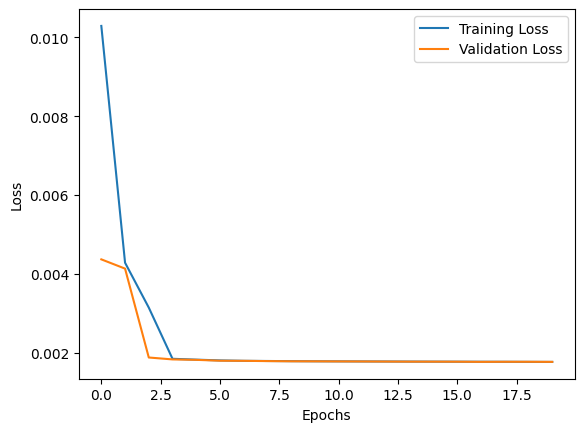

In [11]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [12]:
predictions = model.predict(x_train)

train_errors = np.mean(np.square(x_train - predictions), axis=1)

threshold = np.mean(train_errors) + np.std(train_errors)

print("Anomaly Threshold:", threshold)

7108/7108 ━━━━━━━━━━━━━━━━━━━━ 2s 209us/step
Anomaly Threshold: 0.0033500316507923704


In [13]:
predictions = model.predict(x_test)

errors = np.mean(np.square(x_test - predictions), axis=1)

anomalies = (errors > threshold).astype(int)

print("Number of detected fraud transactions:", np.sum(anomalies))

1781/1781 ━━━━━━━━━━━━━━━━━━━━ 0s 207us/step
Number of detected fraud transactions: 4636


In [14]:
print("Accuracy:", accuracy_score(y_test, anomalies))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, anomalies))

print("\nClassification Report:")
print(classification_report(y_test, anomalies))

Accuracy: 0.9199817422141077

Confusion Matrix:
[[52316  4548]
 [   10    88]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.92      0.96     56864
           1       0.02      0.90      0.04        98

    accuracy                           0.92     56962
   macro avg       0.51      0.91      0.50     56962
weighted avg       1.00      0.92      0.96     56962

